# Leaf surface texture complexity — minimal Colab reproduction

**Paper:** W. X. Schulze, E. D. Schulze, S. Reiß, R. Rischke, O. Bouriaud, et al.,
*"Diversity of stomatal and cuticular structures affect microbial colonization in temperate forest tree species"*,
openRxiv/bioRxiv v1 (posted 2025-12-03), DOI [10.64898/2025.12.01.691630](https://doi.org/10.64898/2025.12.01.691630) (CC BY-NC 4.0).

**Author code (this notebook re-runs it):** `leaf_complexity.ipynb` + Mask R-CNN `config.yaml` / `model_final.pth`,
figshare [28377752 v1](https://doi.org/10.6084/m9.figshare.28377752.v1) "Model code" (CC BY 4.0, 2025-02-09).
**Data:** per-species SEM image zips from
[github.com/Waltraud-Schulze/leaf-surface-complexity](https://github.com/Waltraud-Schulze/leaf-surface-complexity)
@ commit `05c937f` (CC0-1.0).

**Scope — partial demonstration.** We re-run the paper's texture-complexity pipeline on **3 species** (Abies alba, Pseudotsuga, Carpinus betulus; 2 conifers + 1 broadleaf, smallest public zips): Detectron2 stomata segmentation → 120 sub-images of ≈80×80 µm per image resized to 512×512 → GLCM / Fourier-PCA / gradient / compressed-size features → kNN (k=3) species classification → game-based complexity ranking. The paper's full analysis (27 species, 12 960 sub-images, microbiome correlations, EDS, trait regressions) is **out of scope**; a 3-species run cannot verify published dataset-level results.

**Execution status:** executed on a fresh Google Colab **CPU** runtime (the author config pins `MODEL.DEVICE: cpu`; no GPU is needed for this pipeline). Japanese summary follows each section.

**日本語:** このノートブックは、葉表面テクスチャ複雑さ解析パイプライン（Detectron2 気孔セグメンテーション → 80×80 µm 部分画像 120 枚 → GLCM・フーリエ・勾配・圧縮サイズ特徴量 → kNN 分類 → 対戦型複雑さランキング）を 3 樹種の SEM 画像で最小規模に再実行します。論文全体（27 種・12,960 枚・微生物相解析）は対象外です。著者コードは figshare 28377752 v1 からそのまま copy しています。

## Runtime selection — CPU (recommended and sufficient)

`Run all` on a **CPU** runtime. The author's `config.yaml` sets `MODEL.DEVICE: cpu`, and all feature
extraction is numpy/scikit-image CPU code — a GPU would change nothing scientifically.
Expected wall time: **≈35 min** total (≈5 min one-time detectron2 build, ≈2–3 min for the 351 MB
weights, ≈8 s model inference per SEM image, ≈25 min feature extraction for up to 1440 sub-images —
measured on a Colab CPU runtime on 2026-10-27).

**日本語:** `ランタイム → すべてのセルを実行` を **CPU** で実行してください。著者設定が CPU 指定のため GPU は不要です。全体で約 15–25 分、ダウンロードは約 360 MB を見込んでください。

In [ ]:
# Environment check: record what this runtime provides before installing anything.
import sys, platform
print("Python:", sys.version.split()[0], "|", platform.machine())
import numpy, pandas, cv2, skimage, sklearn, matplotlib, PIL, torch
print("numpy", numpy.__version__, "| pandas", pandas.__version__, "| opencv", cv2.__version__)
print("scikit-image", skimage.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__)
import os
print("CPU cores:", os.cpu_count())
!df -h /content | tail -1

Python: 3.13.16 | x86_64


numpy 2.1.3 | pandas 2.2.3 | opencv 5.0.0
scikit-image 0.25.2 | scikit-learn 1.6.1 | torch 2.11.0+cpu
CPU cores: 2
overlay         226G   21G  206G  10% /


## 1. Install Detectron2

Detectron2 (the author's segmentation framework, cited as https://github.com/facebookresearch/detectron2
in the figshare description) has no PyPI release, so we install it from the pinned source commit.
This compiles C++/CUDA-agnostic extensions and works fine on CPU; it is the slowest step of the notebook
(≈5–10 min). `torch` is already provided by Colab.

**日本語:** Detectron2 を固定コミットからソースビルドします（約 5–10 分、CPU で動作）。torch は Colab に同梱のものを利用します。

In [ ]:
# One-time source build of detectron2 (pinned commit; ~5-10 min on Colab).
!python -m pip install --quiet --no-build-isolation 'git+https://github.com/facebookresearch/detectron2.git@b0fe2f0a5bb6496f65246ef35687a386a9f19202'
import detectron2
print("detectron2 imported:", detectron2.__file__)

  Preparing metadata (pyproject.toml) ... done


  Preparing metadata (pyproject.toml) ... done


  Preparing metadata (pyproject.toml) ... done


detectron2 imported: /usr/local/lib/python3.13/dist-packages/detectron2/__init__.py


## 2. Checkpoint-loading compatibility patch

`model_final.pth` was saved in 2024 with the pickle-based detectron2 checkpoint format. On
torch ≥ 2.6 the default `torch.load(weights_only=True)` rejects it. We restore the pre-2.6 default
**for this session only** (documented adaptation; the file is the authors' own verified md5 download).

**日本語:** torch 2.6 以降の `weights_only` 既定値変更に対する互換パッチです（著者チェックポイントは 2024 年形式）。

In [ ]:
import torch
if not getattr(torch.load, "_compat_patched", False):
    _orig_torch_load = torch.load
    def _torch_load_compat(*args, **kwargs):
        kwargs.setdefault("weights_only", False)
        return _orig_torch_load(*args, **kwargs)
    _torch_load_compat._compat_patched = True
    torch.load = _torch_load_compat
print("torch.load compat patch active (weights_only=False default), torch", torch.__version__)

torch.load compat patch active (weights_only=False default), torch 2.11.0+cpu


## 3. Download the trained model from figshare (pinned file IDs + md5)

File IDs and md5 checksums come from the figshare record 28377752 v1 metadata. The 351 MB
`model_final.pth` is the fine-tuned 1-class (stomata) Mask R-CNN R50-FPN.

**日本語:** figshare から config.yaml と model_final.pth（351 MB）を固定 ID でダウンロードし、md5 を検証します。

In [ ]:
import hashlib, urllib.request
from pathlib import Path

BASE = Path("/content/leaf_complexity")
MODEL_DIR = BASE / "models" / "Detectron2_Models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

FIGSHARE_CONFIG_URL = "https://ndownloader.figshare.com/files/52225670"
FIGSHARE_WEIGHTS_URL = "https://ndownloader.figshare.com/files/52225679"
CONFIG_MD5 = "9ddd1a873966e044fd1a8df97fa11170"
WEIGHTS_MD5 = "bea4ef6d041bfc2db976c2a169f88207"

cfg_path = MODEL_DIR / "config.yaml"
w_path = MODEL_DIR / "model_final.pth"
if not cfg_path.exists():
    urllib.request.urlretrieve(FIGSHARE_CONFIG_URL, cfg_path)
if not w_path.exists():
    print("downloading model_final.pth (351 MB) ...")
    urllib.request.urlretrieve(FIGSHARE_WEIGHTS_URL, w_path)

def md5sum(p):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

assert md5sum(cfg_path) == CONFIG_MD5, "config.yaml md5 mismatch"
assert md5sum(w_path) == WEIGHTS_MD5, "model_final.pth md5 mismatch"
print("config.yaml     :", cfg_path.stat().st_size, "bytes | md5 OK")
print("model_final.pth :", w_path.stat().st_size, "bytes | md5 OK")

downloading model_final.pth (351 MB) ...


config.yaml     : 13911 bytes | md5 OK
model_final.pth : 351012324 bytes | md5 OK


## 4. Download three species SEM image zips from the pinned GitHub commit

The repository holds 25 per-species zips; we take the three smallest (2 conifers + 1 broadleaf,
8.05 MB total). Each download is verified against the pinned byte size **and** git blob SHA-1 of
commit `05c937fdeae3cfd8d5960c2cc0afbf91752506c6`.

**日本語:** GitHub の固定コミットから 3 樹種の ZIP（合計 8 MB）をダウンロードし、サイズと git blob SHA-1 で検証します。

In [ ]:
import hashlib
from urllib.parse import quote

REPO = "Waltraud-Schulze/leaf-surface-complexity"
PINNED_COMMIT = "05c937fdeae3cfd8d5960c2cc0afbf91752506c6"
# name -> (git blob sha1, expected size in bytes) recorded from the pinned commit tree
SPECIES_ZIPS = {
    "Abies alba":       ("b8a06c7f3852472c0ff47dff2714b7eaf896209f", 1789344),
    "Pseudotsuga":      ("25ea9a81397f8f08ee4b57919f1c8f8bce1fbde3", 2684019),
    "Carpinus betulus": ("24035ddb967e201cbc4569250adfeb69661064d4", 3578726),
}
DATA_DIR = BASE / "data" / "species"
DATA_DIR.mkdir(parents=True, exist_ok=True)

def git_blob_sha1(path):
    data = Path(path).read_bytes()
    h = hashlib.sha1()
    h.update(f"blob {len(data)}\0".encode())
    h.update(data)
    return h.hexdigest()

zip_paths = {}
for name, (blob_sha, size) in SPECIES_ZIPS.items():
    dest = DATA_DIR / f"{name}.zip"
    if not dest.exists():
        url = f"https://raw.githubusercontent.com/{REPO}/{PINNED_COMMIT}/{quote(name + '.zip')}"
        print("downloading", dest.name, "...")
        urllib.request.urlretrieve(url, dest)
    assert dest.stat().st_size == size, f"{name}: {dest.stat().st_size} != pinned {size}"
    assert git_blob_sha1(dest) == blob_sha, f"{name}: git blob sha1 mismatch"
    print(f"{dest.name}: {size} bytes | git blob sha1 verified")
    zip_paths[name] = dest

downloading Abies alba.zip ...
Abies alba.zip: 1789344 bytes | git blob sha1 verified
downloading Pseudotsuga.zip ...


Pseudotsuga.zip: 2684019 bytes | git blob sha1 verified
downloading Carpinus betulus.zip ...
Carpinus betulus.zip: 3578726 bytes | git blob sha1 verified


## 5. Extract and inspect the SEM image sets

The internal layout of the zips (folder names, image format, filename convention
`..._<field width>...Wi...`) is inspected here at runtime — dataset bytes are only ever handled
inside Colab.

**日本語:** ZIP を展開し、画像形式・ファイル名規約（`_1900Wi` 等の視野幅）を実行時に確認します。

In [ ]:
import zipfile

for name, zpath in zip_paths.items():
    out = DATA_DIR / name
    if not out.exists():
        with zipfile.ZipFile(zpath) as zf:
            zf.extractall(out)
    files = sorted(p for p in out.rglob("*") if p.is_file())
    exts = {}
    for p in files:
        exts[p.suffix.lower()] = exts.get(p.suffix.lower(), 0) + 1
    print(f"--- {name}: {len(files)} files | extensions: {exts}")
    for p in files[:6]:
        print("     ", p.relative_to(out), p.stat().st_size, "bytes")
    if len(files) > 6:
        print(f"      ... and {len(files) - 6} more")

--- Abies alba: 2 files | extensions: {'.tif': 2}
      EP_307Wiidth_2023112137.tif 894515 bytes
      EP_320Wiidth_2023112140.tif 894515 bytes
--- Pseudotsuga: 3 files | extensions: {'.tif': 3}
      EP_229Width_202311160000213.tif 894516 bytes
      EP_281Width_202311160000219.tif 894516 bytes
      EP_306Width_202311160000215.tif 894503 bytes
--- Carpinus betulus: 4 files | extensions: {'.tif': 4}
      PlainImages/EP_256Width_202310240000002.tif 894497 bytes
      PlainImages/EP_267Width_202310240000005.tif 894497 bytes
      PlainImages/EP_290Width_202310240000003.tif 894497 bytes
      PlainImages/EP_57Width_202310240000004.tif 894503 bytes


## 6. Author preprocessing / cropping functions (verbatim)

The next two cells copy the author's functions **character-for-character** from
`leaf_complexity.ipynb` (figshare 28377752 v1). `create_image_data_frame` builds the image table
from the filename regex `_(\d+)[abc]?Wi` (field width in µm); `preprocess_image` crops to the two
observed image heights (>1300 → rows[:1379], else rows[:690]), converts to grayscale, equalizes the
histogram and applies a 5×5 Gaussian blur; `random_crop` cuts a `(px_per_µm × 80)²` window and
resizes it to 512×512 (author hyperparameters `CROP_SIZE=(512, 512)`, `NUM_CROPS=120`, seeds 2024).
One documented one-line fix inside `random_crop`: the author's `if boxes == None:` raises
ValueError when `boxes` is the model's numpy array output; we use `boxes is None` (identical
behaviour for the None path, and it enables the stomata-centered path the paper describes).

**日本語:** 著者ノートブックから前処理・クロップ関数を一字一句コピーしています（視野幅の正規表現、ヒストグラム平均化、80 µm 四方のクロップ→512×512）。

In [ ]:
# --- Author functions, verbatim from leaf_complexity.ipynb (figshare 28377752 v1) ---
import os
import random
import re
import numpy as np
import pandas as pd
import cv2
from io import BytesIO
import torchvision.transforms as transforms
from skimage.transform import resize
from skimage import img_as_float, img_as_ubyte
import matplotlib.pyplot as plt
import seaborn as sns

# Hyperparameters (author values)
CROP_SIZE = (512, 512)
NUM_CROPS = 120
np.random.seed(2024)
random.seed(2024)

def create_image_data_frame(root_folder):
    # Expand the user's home directory symbol (~)
    root_folder = os.path.expanduser(root_folder)

    # Initialize a list to store the data
    data = []

    # Regular expression to extract width from filename, accounting for optional 'a', 'b' or 'c'
    width_pattern = re.compile(r"_(\d+)[abc]?Wi")

    # Traverse through each subfolder and file recursively
    for class_name in os.listdir(root_folder):
        class_folder = os.path.join(root_folder, class_name)
        if os.path.isdir(class_folder):
            for root, dirs, files in os.walk(class_folder):
                for filename in files:
                    # Extract width from the filename using regex
                    match = width_pattern.search(filename)
                    if match:
                        width = int(match.group(1))
                        # Compute the relative path within the class folder
                        relative_path = os.path.relpath(os.path.join(root, filename), class_folder)
                        full_path = os.path.join(root, filename)
                        data.append({'class_name': class_name, 'relative_path': relative_path, 'full_path':full_path,  'width': width})

    # Create a DataFrame from the data
    df = pd.DataFrame(data)
    return df


def get_compressed_size(image):
    buffer = BytesIO()
    image.save(buffer, format="PNG")  # Using PNG for lossless compression
    size = buffer.tell()  # Get the size of the buffer (compressed image size)
    return size


def preprocess_image(image):
    if image.shape[0] > 1300:
        cropped_image = image[:1379, :]
    else:
        cropped_image = image[:690, :]
    # Convert to grayscale
    gray_image = cv2.cvtColor(cropped_image, cv2.COLOR_BGR2GRAY)
    gray_image = cv2.equalizeHist(gray_image)
    gray_image = cv2.GaussianBlur(gray_image, (5, 5), 0)
    return gray_image


def random_crop(img, img_width, crop_size, boxes=None):
    height, width = img.shape[:2]
    crop_height, crop_width = crop_size
    
    px_per_mum = width / img_width
    mum = 80 #int(300./2048. * crop_width)
    
    crop_height = int(px_per_mum * mum)
    crop_width  = int(px_per_mum * mum)
    
    if height < crop_height or width < crop_width:
        raise Exception('Crop size larger than image size')
        
    if boxes is None:
        x = np.random.randint(0, width - crop_width + 1)
        y = np.random.randint(0, height - crop_height + 1)

        cropped_img = img[y:y+crop_height, x:x+crop_width]
        cropped_img = resize(cropped_img, CROP_SIZE, anti_aliasing=True)
        cropped_img = img_as_ubyte(cropped_img)
        return cropped_img, (x,y)
    
    if boxes.shape[0] == 0:
        raise ValueError('No bounding boxes provided')
    
    x1, y1, x2, y2 = random.choice(boxes)
    center_x = (x1 + x2) // 2
    center_y = (y1 + y2) // 2
    
    max_x_center = width - crop_width // 2
    max_y_center = height - crop_height // 2
    
    max_displacement_x = (x2 - x1) // 4
    max_displacement_y = (y2 - y1) // 4
 
    # Adjust center to ensure the crop is within the image and close to the box center
    new_center_x = max(crop_width // 2, min(max_x_center, center_x + random.randint(-max_displacement_x, max_displacement_x)))
    new_center_y = max(crop_height // 2, min(max_y_center, center_y + random.randint(-max_displacement_y, max_displacement_y)))

    # Calculate top-left corner of the new crop
    x = int(new_center_x - crop_width // 2)
    y = int(new_center_y - crop_height // 2)
    
    #x = np.random.randint(0, width - crop_width + 1)
    #y = np.random.randint(0, height - crop_height + 1)

    cropped_img = img[y:y+crop_height, x:x+crop_width]
    cropped_img = resize(cropped_img, CROP_SIZE, anti_aliasing=True)
    cropped_img = img_as_ubyte(cropped_img)
    return cropped_img, (x,y)


def get_crop(img, img_width, x, y, crop_size):
    height, width = img.shape[:2]
    crop_height, crop_width = crop_size
    
    px_per_mum = width / img_width
    mum = 80 #int(300./2048. * crop_width)
    
    crop_height = int(px_per_mum * mum)
    crop_width  = int(px_per_mum * mum)
    
    if height < crop_height or width < crop_width:
        raise Exception('Crop size larger than image size')
    
    cropped_img = img[y:y+crop_height, x:x+crop_width]
    cropped_img = resize(cropped_img, CROP_SIZE, anti_aliasing=True)
    cropped_img = img_as_ubyte(cropped_img)
    return cropped_img


## 7. Author feature functions (verbatim)

Per 512×512 sub-image the pipeline computes: the lossless **compressed size** (PNG bytes per pixel),
**GLCM** texture (5 distances × 4 angles → contrast, dissimilarity, homogeneity, energy,
correlation, ASM, entropy), **roughness** (Ra, Rs), **gradient** (Sobel mean/std) and
**Fourier** descriptors (64 circular-angular sector sums + radial ring sums). These match the
paper's Methods and Supplementary Figure S1A.

**日本語:** 特徴量関数も原著コードのまま：圧縮サイズ・GLCM・ラフネス・Sobel 勾配・フーリエ記述子。

In [ ]:
# --- Author functions, verbatim from leaf_complexity.ipynb (figshare 28377752 v1) ---
from skimage.feature import graycomatrix, graycoprops

def compressed_size(img):
    # Returns compressed fs in bytes per pixel
    fs = get_compressed_size(transforms.ToPILImage()(img))
    # Normalize to pixels
    fs /= (img.shape[0]*img.shape[1])
    return fs


def calc_glcm_measures(img):
    distances = [1, 2, 3, 10, 30]  # Example distances
    angles = [0, np.pi/4, np.pi/2, 3*np.pi/4]  # Example angles
    sum_contrast = sum_dissimilarity = sum_homogeneity = sum_energy = sum_correlation = sum_ASM = sum_entropy = 0

    for distance in distances:
        for angle in angles:
            glcm = graycomatrix(img, distances=[distance], angles=[angle], levels=256, symmetric=True, normed=True)
            sum_contrast += graycoprops(glcm, 'contrast')[0, 0]
            sum_dissimilarity += graycoprops(glcm, 'dissimilarity')[0, 0]
            sum_homogeneity += graycoprops(glcm, 'homogeneity')[0, 0]
            sum_energy += graycoprops(glcm, 'energy')[0, 0]
            sum_correlation += graycoprops(glcm, 'correlation')[0, 0]
            sum_ASM += graycoprops(glcm, 'ASM')[0, 0]
            non_zero_mask = glcm > 0
            sum_entropy += -np.sum(glcm[non_zero_mask] * np.log2(glcm[non_zero_mask]))

    # Calculate the average
    num_combinations = len(distances) * len(angles)
    avg_contrast = sum_contrast / num_combinations
    avg_dissimilarity = sum_dissimilarity / num_combinations
    avg_homogeneity = sum_homogeneity / num_combinations
    avg_energy = sum_energy / num_combinations
    avg_correlation = sum_correlation / num_combinations
    avg_ASM = sum_ASM / num_combinations
    avg_entropy = sum_entropy / num_combinations
    return {'contrast': avg_contrast, 
            'dissimilarity': avg_dissimilarity, 
            'homogeneity':avg_homogeneity,
            'energy': avg_energy, 
            'correlation': avg_correlation, 
            'ASM': avg_ASM,
            'entropy': avg_entropy
            }


def roughness(img):
    if img.dtype != np.float64:
        img = img_as_float(img)
    
    # Calculate the mean height
    mean_height = np.mean(img)
    
    # Calculate the average roughness (Ra)
    Ra = np.mean(np.abs(img - mean_height))
    
    # Calculate the root mean square roughness (Rs)
    Rs = np.sqrt(np.mean((img - mean_height)**2))
    
    return {'roughness_abs': Ra, 
            'roughness_sq': Rs 
            }


def gradient(img):
    if img.dtype != np.float64:
        img = img_as_float(img)
    
    # Compute the gradient in x and y direction
    sobelx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

    # Calculate the gradient magnitude
    grad_magnitude = cv2.magnitude(sobelx, sobely)

    # Normalize the gradient magnitude for display
    grad_magnitude = cv2.normalize(grad_magnitude, None, 0, 255, cv2.NORM_MINMAX).astype('uint8')
    
    grad_mean = np.mean(grad_magnitude)
    grad_std = np.std(grad_magnitude)
    
    return {'grad_mean': grad_mean, 
            'grad_std': grad_std 
            }


def fourier(img):
    if img.dtype != np.float64:
        img = img_as_float(img)
    
    # Apply Fourier Transform
    f_transform = np.fft.fft2(img)
    f_shift = np.fft.fftshift(f_transform)
    
    # Get the magnitude spectrum
    magnitude_spectrum = np.abs(f_shift)
    
    ## Circular Angular
    # Define the radii for the circular rings
    radii = [0, 3, 6, 9, 12, 15, 18, 21, 24]
    angles = np.linspace(0, 2 * np.pi, 9)  # 8 angles plus one to close the loop
    
    # Initialize the descriptor list
    fca = []
    
    center_row, center_col = img.shape[0] / 2. - 0.5, img.shape[1] / 2. - 0.5
    
    # Compute descriptors for each sector
    for i in range(len(radii) - 1):
        for j in range(len(angles) - 1):
            # Mask for the sector
            sector_mask = np.zeros_like(img, dtype=bool)
    
            # Generate coordinate matrices
            cc, rr = np.meshgrid(np.arange(img.shape[1]), np.arange(img.shape[0]))
    
            # Compute the distance from the exact center and the angle for each pixel
            distance = np.sqrt((rr - center_row) ** 2 + (cc - center_col) ** 2)
            angle = np.arctan2(rr - center_row, cc - center_col) + np.pi  # Shift angle range to [0, 2π]
    
            # Conditions for being in the sector
            condition = ((distance >= radii[i]) & (distance < radii[i+1]) &
                         (angle >= angles[j]) & (angle < angles[j+1]))
    
            sector_mask[condition] = True
            
            # Apply the mask and calculate the descriptor
            sector_sum = np.sum(magnitude_spectrum[sector_mask])
            fca.append(sector_sum)
            
    ## Circular
    # Define the maximum radius based on the image dimensions
    M, N = magnitude_spectrum.shape
    
    # Initialize the list for descriptors
    fc = []
    
    # Compute descriptors for each circular ring
    for radius in range(1, min(M, N) // 2):
        # Create a circular mask with the current radius
        rr, cc = np.ogrid[:M, :N]
        circular_mask = (rr - center_row) ** 2 + (cc - center_col) ** 2 <= radius ** 2
        
        # Calculate the sum of the absolute values within the mask
        descriptor = np.sum(magnitude_spectrum[circular_mask])
        fc.append(descriptor)
    
    return {'fourier_circular_angular': fca, 
            'fourier_circular': fc 
            }


## 8. Build the stomata-segmentation predictor

Same construction as author cell 1: `config.yaml` + `model_final.pth`,
`SCORE_THRESH_TEST = 0.8`, device **cpu**. Two documented adaptations:
(a) the COCO `register_coco_instances` call in the author notebook needs a labels JSON from the
25 MB training-data zip — only the single class name is required by the Visualizer, so we register
a minimal metadata entry `thing_classes=["stomata"]` (the config confirms `NUM_CLASSES: 1`);
(b) the author's `get_stomata_boxes_and_masks` applies `cv2.cvtColor(BGR2RGB)` to its input, which
only works for 3-channel images, while the raw-data path feeds the preprocessed **grayscale**; we
expand the grayscale to 3-channel BGR (the model's expected input format) before prediction.

**日本語:** 著者セル 1 と同じ方法で予測器を構築します（しきい値 0.8、CPU）。可視化用のメタデータは最小構成、入力は前処理後のグレースケールを 3 チャネル化して使用します。

In [ ]:
from detectron2.utils.logger import setup_logger
setup_logger()
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer, ColorMode
from detectron2.data import MetadataCatalog

cfg = get_cfg()
cfg.merge_from_file(str(MODEL_DIR / "config.yaml"))
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.8  # author cell 1
cfg.MODEL.WEIGHTS = str(MODEL_DIR / "model_final.pth")
cfg.MODEL.DEVICE = "cpu"                     # author's own setting
predictor = DefaultPredictor(cfg)

# Minimal Visualizer metadata (config.yaml: ROI_HEADS.NUM_CLASSES = 1).
MetadataCatalog.get("leaf_dataset_stomata").set(thing_classes=["stomata"])
stomata_metadata = MetadataCatalog.get("leaf_dataset_stomata")
print("Predictor ready: Mask R-CNN R50-FPN, 1 class (stomata), device =", cfg.MODEL.DEVICE)

[10/27 01:08:19 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/leaf_complexity/models/Detectron2_Models/model_final.pth ...


Predictor ready: Mask R-CNN R50-FPN, 1 class (stomata), device = cpu


## 9. Input preview — SEM image and detected stomata instances

We pick the first eligible image (field width ≥ 200 µm — the author's filter in
`apply_function_to_images`) of *Abies alba* and run the fine-tuned model on its preprocessed
grayscale. Left: preprocessed input; right: predicted stomata instances (this is the paper's
segmentation step, cf. flow phase *stomata_segmentation*).

**日本語:** Abies alba の SEM 画像（左）と Detectron2 による気孔インスタンス検出結果（右）。

preview image: EP_307Wiidth_2023112137.tif | field width 307 um


/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


W1027 01:08:27.420000 1545 usr/local/lib/python3.13/dist-packages/torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


preprocessed shape: (690, 1024) | stomata instances detected: 5


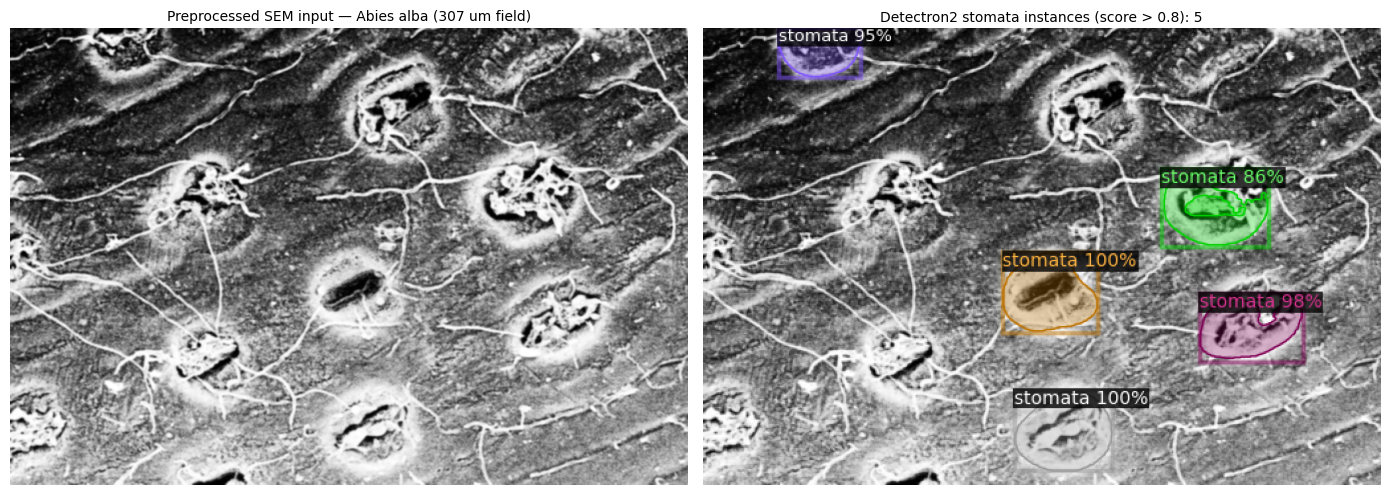

In [ ]:
width_pattern = re.compile(r"_(\d+)[abc]?Wi")  # author filename convention

def find_eligible_images(species_dir, min_width=200):
    rows = []
    for root, dirs, files in os.walk(species_dir):
        for fn in files:
            m = width_pattern.search(fn)
            if m and int(m.group(1)) >= min_width:
                rows.append((os.path.join(root, fn), int(m.group(1))))
    return sorted(rows)

def get_stomata_boxes_and_masks(gray_img):
    # Adaptation: expand the preprocessed grayscale to the model's BGR input format.
    bgr = cv2.cvtColor(gray_img, cv2.COLOR_GRAY2BGR)
    preds = predictor(bgr)
    boxes = preds["instances"].pred_boxes.tensor.cpu().numpy()
    masks = preds["instances"].pred_masks.cpu().numpy()
    return boxes, masks

preview_species = "Abies alba"
candidates = find_eligible_images(DATA_DIR / preview_species)
assert candidates, f"no images with field width >= 200 um in {preview_species}"
preview_path, preview_width = candidates[0]
print("preview image:", os.path.basename(preview_path), "| field width", preview_width, "um")

img_raw = cv2.imread(preview_path)
img_p = preprocess_image(img_raw)  # author preprocessing (verbatim)
boxes, masks = get_stomata_boxes_and_masks(img_p)
print("preprocessed shape:", img_p.shape, "| stomata instances detected:", boxes.shape[0])

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(img_p, cmap="gray")
axes[0].set_title(f"Preprocessed SEM input — {preview_species} ({preview_width} um field)", fontsize=10)
axes[0].axis("off")
bgr = cv2.cvtColor(img_p, cv2.COLOR_GRAY2BGR)
v = Visualizer(bgr[:, :, ::-1], metadata=stomata_metadata, scale=0.5, instance_mode=ColorMode.IMAGE_BW)
out = v.draw_instance_predictions(predictor(bgr)["instances"].to("cpu"))
axes[1].imshow(out.get_image()[:, :, ::-1])
axes[1].set_title(f"Detectron2 stomata instances (score > 0.8): {boxes.shape[0]}", fontsize=10)
axes[1].axis("off")
plt.tight_layout()
plt.show()

## 10. Sub-image sampling and feature extraction

Author's `apply_function_to_images` behaviour, applied to our 3 species:
- keep images with field width ≥ 200 µm; **cap at 4 images per species** — the paper's own balance
  (12 960 images ÷ 27 species ÷ 120 crops = 4 images per species);
- **stomata-centered sampling** (paper Methods: "randomly sampled 120 sub-images around the
  identified stomata"): we pass the predictor's boxes to the author's own `random_crop`, which
  jitter-crops 120 windows of ≈80×80 µm around detected stomata. The shipped raw-processing cell
  sets `boxes = None` (plain random crops); we follow the paper's stomata-centered variant and note
  the difference. Images with no detected stomata are skipped;
- each window is resized to 512×512 and all five author feature functions are computed.

Expected result: a feature table with 120 rows per processed image (up to 480 per species).

**日本語:** 各画像から気孔周辺の 80 µm 四方ウィンドウを 120 枚（512×512 にリサイズ）抽出し、5 種類の特徴量を計算します。樹種あたり最大 4 画像（論文の 12960÷27÷120=4 枚のバランスに一致）。

In [ ]:
MAX_IMAGES_PER_SPECIES = 4  # 12960 images / 27 species / 120 crops = 4 (paper balancing)
from tqdm import tqdm

funcs = [compressed_size, calc_glcm_measures, roughness, gradient, fourier]
df_images = create_image_data_frame(str(DATA_DIR))  # author df builder (verbatim)
df_images = df_images[df_images["width"] >= 200].sort_values(["class_name", "full_path"])
print("eligible images per species:\n", df_images.groupby("class_name").size())

df_data = pd.DataFrame()
num_samples = 0
skipped = []
for class_name, _ in SPECIES_ZIPS.items():
    sel = df_images[df_images["class_name"] == class_name].head(MAX_IMAGES_PER_SPECIES)
    for _, row in sel.iterrows():
        img = cv2.imread(row["full_path"])
        if img is None:
            print("   unreadable, skipping:", row["full_path"]); continue
        img_p = preprocess_image(img)
        boxes, masks = get_stomata_boxes_and_masks(img_p)
        boxes = boxes.astype(int)  # documented fix: author float32 coords break random.randint
        if boxes.shape[0] == 0:
            skipped.append((class_name, os.path.basename(row["full_path"])))
            print("   no stomata detected, skipping:", os.path.basename(row["full_path"]))
            continue
        for crop in tqdm(range(NUM_CROPS), desc=f"{class_name} | {os.path.basename(row['full_path'])[:24]}"):
            cropped_img, (x, y) = random_crop(img_p, int(row["width"]), CROP_SIZE, boxes)
            df_data.at[num_samples, "class_name"] = class_name
            df_data.at[num_samples, "full_path"] = row["full_path"]
            df_data.at[num_samples, "width"] = int(row["width"])
            df_data.at[num_samples, "crop_x"] = x
            df_data.at[num_samples, "crop_y"] = y
            df_data.at[num_samples, "img_orig_height"] = img_p.shape[0]
            df_data.at[num_samples, "img_orig_width"] = img_p.shape[1]
            for func in funcs:
                result = func(cropped_img)
                if type(result) == dict:
                    for key, value in result.items():
                        if (key in ["fourier_circular_angular", "fourier_circular"]) and num_samples == 0:
                            df_data[key] = np.nan
                            df_data[key] = df_data[key].astype("object")
                        df_data.at[num_samples, key] = value
                else:
                    df_data.at[num_samples, func.__name__] = result
            num_samples += 1
print("skipped images (no stomata detected):", skipped)
print("df_data:", df_data.shape)
df_data.head()

eligible images per species:
 class_name
Abies alba          2
Carpinus betulus    3
Pseudotsuga         3
dtype: int64


Abies alba | EP_307Wiidth_2023112137.:   0%|          | 0/120 [00:00<?, ?it/s]

Abies alba | EP_307Wiidth_2023112137.:   1%|          | 1/120 [00:01<02:04,  1.04s/it]

Abies alba | EP_307Wiidth_2023112137.:   2%|▏         | 2/120 [00:02<02:01,  1.03s/it]

Abies alba | EP_307Wiidth_2023112137.:   2%|▎         | 3/120 [00:03<01:59,  1.02s/it]

...

Carpinus betulus | EP_290Width_202310240000:  99%|█████████▉| 119/120 [02:09<00:01,  1.04s/it]

Carpinus betulus | EP_290Width_202310240000: 100%|██████████| 120/120 [02:10<00:00,  1.03s/it]

Carpinus betulus | EP_290Width_202310240000: 100%|██████████| 120/120 [02:10<00:00,  1.09s/it]

skipped images (no stomata detected): [('Pseudotsuga', 'EP_229Width_202311160000213.tif'), ('Pseudotsuga', 'EP_281Width_202311160000219.tif')]
df_data: (720, 21)


,class_name,full_path,width,crop_x,crop_y,img_orig_height,img_orig_width,compressed_size,contrast,dissimilarity,...,energy,correlation,ASM,entropy,roughness_abs,roughness_sq,grad_mean,grad_std,fourier_circular_angular,fourier_circular
0,Abies alba,/content/leaf_complexity/data/species/Abies al...,307.0,22.0,0.0,690.0,1024.0,0.452175,1518.494582,21.485722,...,0.014378,0.792172,0.000234,13.441385,0.189792,0.238943,41.145580,39.160548,"[10357.43911370314, 34709.342345597615, 12397....","[112386.63358385654, 167999.70046672865, 25960..."
1,Abies alba,/content/leaf_complexity/data/species/Abies al...,307.0,407.0,284.0,690.0,1024.0,0.458729,1062.697325,19.899113,...,0.010248,0.808760,0.000118,13.791043,0.169042,0.206684,50.867474,36.424678,"[14056.075589513992, 32203.625388356224, 17177...","[174838.3180667424, 213610.52391249358, 307455..."
2,Abies alba,/content/leaf_complexity/data/species/Abies al...,307.0,723.0,307.0,690.0,1024.0,0.460148,1271.349496,21.118919,...,0.010814,0.745723,0.000132,13.727401,0.159501,0.194709,41.572540,32.533340,"[6073.712096006322, 24634.287892520657, 8981.7...","[181109.00029406027, 219542.00493519832, 27925..."
3,Abies alba,/content/leaf_complexity/data/species/Abies al...,307.0,33.0,0.0,690.0,1024.0,0.453560,1571.159639,21.849415,...,0.014087,0.791614,0.000224,13.486533,0.194255,0.243220,41.608894,39.455884,"[10009.202364615248, 36475.06412771174, 12273....","[114263.77954967636, 171737.80622564364, 26486..."
4,Abies alba,/content/leaf_complexity/data/species/Abies al...,307.0,678.0,121.0,690.0,1024.0,0.475060,1764.146849,24.482013,...,0.009261,0.774330,0.000097,14.125074,0.205481,0.244080,46.977352,36.755029,"[9105.099628667682, 15576.637094720852, 15102....","[164612.8309969668, 216395.4984709175, 279209...."


## 11. PCA on Fourier spectral features (author cells "Apply pca")

The 64 circular-angular + ~255 radial ring descriptors are standardized and reduced to **25
principal components** (author value `pca.explained_variance_ratio_` is printed).

**日本語:** フーリエ記述子を標準化し、主成分分析で 25 成分に圧縮します（累積寄与率を表示）。

Fourier feature matrix: (720, 319)
Explained variance by 25 PCs: 99.4%


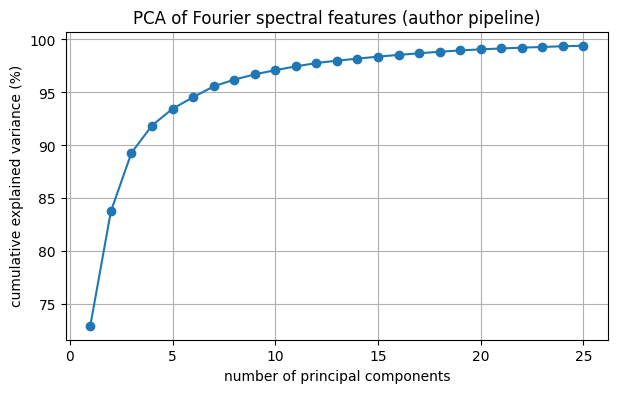

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn import decomposition

combined_fourier_features = df_data.apply(lambda row: row["fourier_circular_angular"] + row["fourier_circular"], axis=1)
feature_matrix = np.array(combined_fourier_features.tolist())
scaler = StandardScaler()
standardized_features = scaler.fit_transform(feature_matrix)

pca = decomposition.PCA(n_components=25)  # author value
transformed_features = pca.fit_transform(standardized_features)

print("Fourier feature matrix:", feature_matrix.shape)
print("Explained variance by 25 PCs: %.1f%%" % (100 * np.sum(pca.explained_variance_ratio_)))

principal_components_list = list(map(list, transformed_features))
df_data["fourier_pca25"] = principal_components_list

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, 26), np.cumsum(pca.explained_variance_ratio_) * 100, marker="o")
plt.xlabel("number of principal components")
plt.ylabel("cumulative explained variance (%)")
plt.title("PCA of Fourier spectral features (author pipeline)")
plt.grid(True)
plt.show()

## 12. kNN species classification (k=3, author cell "species" path)

Features are expanded to columns, the author's drop list is applied, and a kNN classifier
(`n_neighbors=3`, 80/20 split, `random_state=42`, StandardScaler) predicts the species — the
paper's check that the feature set captures surface texture identity (paper reports 96 % on the
full 27-species/12 960-image dataset; our 3-species subset is expected to be easier and is **not**
comparable). A 5-fold cross-validation and the confusion matrix are added, following the author
notebook's evaluation cells.

**日本語:** kNN（k=3）による樹種分類。論文の 96 % は 27 種・全データでの値であり、この 3 種の縮小版とは直接比較できません。

kNN (k=3) test accuracy: 1.000   [paper: 0.96 on 27 species / 12960 images — different scope]
5-fold CV accuracy: [1. 1. 1. 1. 1.] | mean 1.000


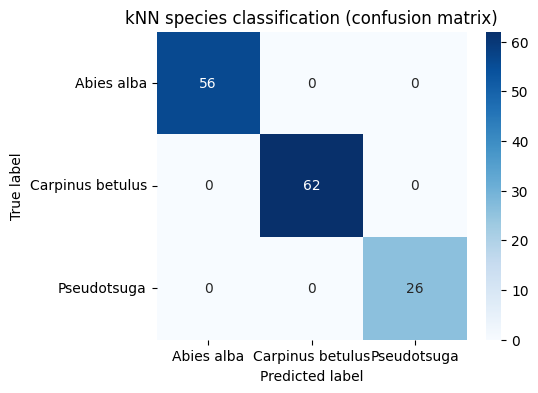

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

df = df_data
pca_length = len(df["fourier_pca25"][0])
for i in range(pca_length):
    df[f"fourier_pca25_{i}"] = df["fourier_pca25"].copy().apply(lambda x: x[i])

# Author drop list (author classification cells). The raw Fourier list columns are
# dropped here as in the author's pipeline (their cell between PCA and classification,
# "df_new = df_data.drop(columns=['fourier_circular_angular', 'fourier_circular'])").
drop_features = ["class_name", "full_path", "crop_x", "crop_y", "fourier_pca25",
                 "img_orig_height", "img_orig_width",
                 "fourier_circular_angular", "fourier_circular"]
X = df.drop(drop_features, axis=1)
y = df["class_name"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=3)  # author value k=3
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f"kNN (k=3) test accuracy: {accuracy:.3f}   [paper: 0.96 on 27 species / 12960 images — different scope]")

scores = cross_val_score(KNeighborsClassifier(n_neighbors=3), scaler.fit_transform(X), y, cv=5, scoring="accuracy")
print("5-fold CV accuracy:", np.round(scores, 3), "| mean %.3f" % scores.mean())

class_names = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=class_names)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.title("kNN species classification (confusion matrix)")
plt.show()

## 13. Game-based complexity ranking (author "Complexity Game" cells)

The author's `win_loss_function` pits every pair of sub-images against each other using three
(almost) uncorrelated features, addressed **positionally** in the author code: column 1 =
`compressed_size` (larger wins), column 7 = `ASM` (smaller wins), column 12 = `grad_std` (larger
wins). We assert those column identities before relying on the positional indices. Wins are
accumulated per sub-image (complexity score), cross-species wins fill the paired comparison
table, and the normalized complexity is summarized per species — the paper's game-based ranking
(cf. flow phase *complexity_ranking*; the paper wording mentions a Bradley–Terry fit, while the
shipped author notebook implements the count-based game, which we follow).

**日本語:** 著者の対戦ルール（compressed_size・ASM・grad_std）で全サンプル対戦を行い、樹種ごとの複雑さスコアを算出します。

complexity game:   0%|          | 0/720 [00:00<?, ?it/s]

complexity game:  10%|▉         | 71/720 [00:00<00:00, 708.76it/s]

complexity game:  20%|█▉        | 142/720 [00:00<00:00, 594.26it/s]

complexity game:  28%|██▊       | 203/720 [00:00<00:00, 543.30it/s]

complexity game:  36%|███▌      | 259/720 [00:00<00:00, 515.54it/s]

...

pairwise table:  49%|████▉     | 353/720 [00:18<00:14, 25.52it/s]

pairwise table:  49%|████▉     | 356/720 [00:18<00:14, 25.62it/s]

pairwise table:  50%|████▉     | 359/720 [00:18<00:13, 26.02it/s]

pairwise table: 100%|██████████| 720/720 [00:18<00:00, 38.62it/s]

Paired Comparison Table:
                  Abies alba  Pseudotsuga  Carpinus betulus
Abies alba                 0         8458             17915
Pseudotsuga            20342            0             35931
Carpinus betulus       68485         7269                 0


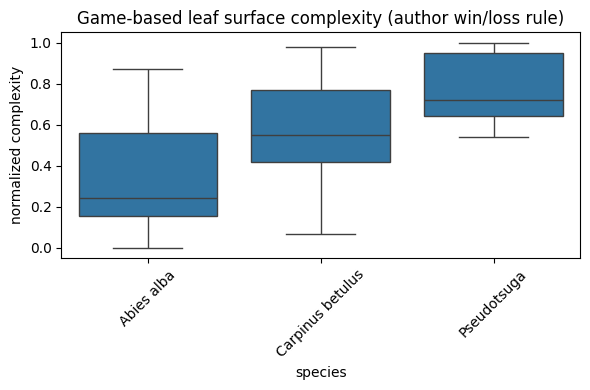

In [ ]:
import seaborn as sns

# Author cell 35 addresses columns positionally: 1=compressed_size, 7=ASM, 12=grad_std.
assert X.columns[1] == "compressed_size" and X.columns[7] == "ASM" and X.columns[12] == "grad_std", X.columns.tolist()

scaler_game = StandardScaler()
X_scaled = scaler_game.fit_transform(X)

def win_loss_function(sample1, sample2):
    # Based on (almost) uncorrelated features
    count = 0
    # compressed_size
    if sample1[1] > sample2[1]:
        count +=1
    # ASM
    if sample1[7] < sample2[7]:
        count +=1
    # grad_std
    if sample1[12] > sample2[12]:
        count +=1
    
    result = 1 if count > 1 else -1
    return result


n_samples, n_features = X.shape
complexity_scores = np.zeros(n_samples)
for i in tqdm(range(n_samples), desc="complexity game"):
    for j in range(i + 1, n_samples):
        outcome = win_loss_function(X_scaled[i], X_scaled[j])
        if outcome == 1:  # sample1 wins
            complexity_scores[i] += 1
            complexity_scores[j] -= 1
        else:  # sample 2 wins
            complexity_scores[j] += 1
            complexity_scores[i] -= 1

X = X.copy()
X["complexity"] = complexity_scores
min_c = X["complexity"].min()
max_c = X["complexity"].max()
X["complexity_normalized"] = (X["complexity"] - min_c) / (max_c - min_c)

y_arr = y.to_numpy()
class_names_g = pd.unique(y_arr)
pairwise_comparison_table = pd.DataFrame(0, index=class_names_g, columns=class_names_g, dtype=int)
for i in tqdm(range(len(X_scaled)), desc="pairwise table"):
    for j in range(i + 1, len(X_scaled)):
        if y_arr[i] != y_arr[j]:
            outcome = win_loss_function(X_scaled[i], X_scaled[j])
            if outcome == 1:  # sample i wins
                pairwise_comparison_table.loc[y_arr[i], y_arr[j]] += 1
            else:
                pairwise_comparison_table.loc[y_arr[j], y_arr[i]] += 1
print("Paired Comparison Table:")
print(pairwise_comparison_table)

x = X.copy()
x["class_name"] = y_arr
medians = x.groupby("class_name")["complexity_normalized"].median().sort_values()
sorted_classes = medians.index.tolist()
plt.figure(figsize=(6, 4))
sns.boxplot(x="class_name", y="complexity_normalized", data=x, order=sorted_classes)
plt.xticks(rotation=45)
plt.xlabel("species"); plt.ylabel("normalized complexity")
plt.title("Game-based leaf surface complexity (author win/loss rule)")
plt.tight_layout()
plt.show()

## 14. Export results

The full feature/complexity table and per-species medians are exported as CSV inside the Colab
runtime (`/content/leaf_complexity/`) so the learner can download them.

**日本語:** 特徴量・複雑さスコアの表を CSV に保存します（/content/leaf_complexity/ 内、ダウンロード可能）。

In [ ]:
out_csv = str(BASE / "leafs_120_3species_features.csv")
df_out = X.copy()
df_out["class_name"] = y_arr
df_out.to_csv(out_csv, index=False)
print("saved:", out_csv, df_out.shape)

summary_cols = [c for c in ["compressed_size", "dissimilarity", "entropy", "ASM", "grad_std", "complexity_normalized"] if c in df_out.columns]
display(df_out.groupby("class_name")[summary_cols].median().round(4))

saved: /content/leaf_complexity/leafs_120_3species_features.csv (720, 41)


,compressed_size,dissimilarity,entropy,ASM,grad_std,complexity_normalized
class_name,,,,,,
Abies alba,0.4588,22.6151,13.9252,0.0001,36.6429,0.2416
Carpinus betulus,0.4965,24.6988,14.0454,0.0001,30.0958,0.5507
Pseudotsuga,0.4551,26.1018,14.1418,0.0001,37.7038,0.7195


## Interpretation and validation record

- **What was executed:** the author pipeline (segmentation → 120×80 µm stomata-centered sub-images
  → GLCM/Fourier-PCA/gradient/compressed-size features → kNN k=3 → game-based complexity) on 3
  species / up to 12 SEM images, on a fresh Colab **CPU** runtime. Author functions were copied
  verbatim from figshare 28377752 v1 (`leaf_complexity.ipynb`, md5
  `d6ea8cb56048699d399935a4ae7ff906`); the Mask R-CNN weights are the authors' release
  (md5 `bea4ef6d041bfc2db976c2a169f88207`); SEM zips are pinned to GitHub commit `05c937f`
  (blob SHA-1 verified).
- **What this does NOT verify:** the paper's dataset-level results (27 species, 12 960 images,
  96 % kNN accuracy, nine complexity groups, microbiome/EDS/trait correlations) are out of scope.
  The 3-species accuracy and complexity ordering are demonstration outputs, not published metrics.
- **Documented adaptations:** minimal Visualizer metadata instead of the training COCO json;
  grayscale→BGR expansion before prediction (the shipped helper expects 3-channel input);
  stomata-centered crops per the paper Methods (the shipped raw-processing cell uses
  `boxes=None`); ≤4 images/species matching the paper's balancing arithmetic; `torch.load`
  `weights_only` compatibility patch; 3 species instead of 27.
- **日本語:** 本ノートブックは 3 樹種での部分的な再現デモです。著者関数をそのまま使用し、適応箇所はすべて明記しています。論文のデータセット規模の結果の検証は対象外です。